<a href="https://colab.research.google.com/github/sylle321/Hotel_booking/blob/main/ba305_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px                          # interactive plots (pre-installed on Colab)
from sklearn.preprocessing import StandardScaler     # does the scaling for us
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from tqdm import tqdm

path = "/content/hotels.csv"
df = pd.read_csv(path)
#Shows each columns data type and number of non-null values.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103785 entries, 0 to 103784
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           103785 non-null  object 
 1   is_canceled                     103784 non-null  float64
 2   lead_time                       103784 non-null  float64
 3   arrival_date_year               103784 non-null  float64
 4   arrival_date_month              103784 non-null  object 
 5   arrival_date_week_number        103784 non-null  float64
 6   arrival_date_day_of_month       103784 non-null  float64
 7   stays_in_weekend_nights         103784 non-null  float64
 8   stays_in_week_nights            103784 non-null  float64
 9   adults                          103784 non-null  float64
 10  children                        103780 non-null  float64
 11  babies                          103784 non-null  float64
 12  meal            

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Counts distinct values in each column of the dataframe.
df.nunique()

,0
hotel,3
is_canceled,2
lead_time,478
arrival_date_year,3
arrival_date_month,12
arrival_date_week_number,53
arrival_date_day_of_month,31
stays_in_weekend_nights,17
stays_in_week_nights,35
adults,14


In [ ]:
# Convert hotel to a dummy variable:
# Resort Hotel = 0, City Hotel = 1
df['hotel'] = df['hotel'].map({
    'Resort Hotel': 0,
    'City Hotel': 1
})

df.head()

# Create dummy variables for the other categorical variables
categorical_cols = [
    'deposit_type',
    'market_segment',
    'customer_type',
    'reserved_room_type'
]

df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103785 entries, 0 to 103784
Data columns (total 49 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           103784 non-null  float64
 1   is_canceled                     103784 non-null  float64
 2   lead_time                       103784 non-null  float64
 3   arrival_date_year               103784 non-null  float64
 4   arrival_date_month              103784 non-null  object 
 5   arrival_date_week_number        103784 non-null  float64
 6   arrival_date_day_of_month       103784 non-null  float64
 7   stays_in_weekend_nights         103784 non-null  float64
 8   stays_in_week_nights            103784 non-null  float64
 9   adults                          103784 non-null  float64
 10  children                        103780 non-null  float64
 11  babies                          103784 non-null  float64
 12  meal            

In [ ]:
# Selecting the columns of interest for analysis
# Making sure unrelated columns are not included in the analysis.
cols = [
    "hotel",
    "is_canceled",
    "lead_time",
    "deposit_type",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "customer_type",
    "booking_changes",
    "is_repeated_guest",
    "market_segment",
    "total_of_special_requests",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "reserved_room_type",
    "adr",
    "distribution_channel",
    "arrival_date_month"
]

hotel_selected = df[cols]

hotel_selected.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103785 entries, 0 to 103784
Data columns (total 17 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           103784 non-null  float64
 1   is_canceled                     103784 non-null  float64
 2   lead_time                       103784 non-null  float64
 3   deposit_type                    103784 non-null  object 
 4   previous_cancellations          103784 non-null  float64
 5   previous_bookings_not_canceled  103784 non-null  float64
 6   customer_type                   103784 non-null  object 
 7   booking_changes                 103784 non-null  float64
 8   is_repeated_guest               103784 non-null  float64
 9   market_segment                  103784 non-null  object 
 10  total_of_special_requests       103784 non-null  float64
 11  stays_in_weekend_nights         103784 non-null  float64
 12  stays_in_week_ni

In [ ]:
#Cleaning the data by removing rows with any missing values and resetting the index.
hotel_clean = hotel_selected.dropna(how="any") #Removes rows with any missing values.
hotel_clean = hotel_clean.reset_index(drop=True) #resets the index

print(hotel_selected.shape)
print(hotel_clean.shape)

(103785, 17)
(103784, 17)


In [ ]:
#Checking cancelation counts and proportions in the cleaned dataset.
print(hotel_clean["is_canceled"].value_counts()) #Gives the count of each unique value in the "is_canceled" column.

print(
    hotel_clean["is_canceled"].value_counts(normalize=True) # Gives the proportion of each unique value in the "is_canceled" column.
)


is_canceled
0.0    59575
1.0    44209
Name: count, dtype: int64
is_canceled
0.0    0.574029
1.0    0.425971
Name: proportion, dtype: float64


In [ ]:
# Calculate the correlation using PCA lab's code as reference.
# We exclude categorical string columns and only keep truly numeric columns
numeric_cols = [
    "is_canceled",
    "lead_time",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "is_repeated_guest",
    "total_of_special_requests",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adr"
]

hotel_numeric = hotel_clean[numeric_cols]

corr_mat = hotel_numeric.corr()

corr_mat.round(4)

,is_canceled,lead_time,previous_cancellations,previous_bookings_not_canceled,booking_changes,is_repeated_guest,total_of_special_requests,stays_in_weekend_nights,stays_in_week_nights,adr
is_canceled,1.0000,0.3198,0.1031,-0.0702,-0.1523,-0.1072,-0.2265,-0.0112,0.0105,0.0937
lead_time,0.3198,1.0000,0.0910,-0.0784,-0.0082,-0.1296,-0.1246,0.0852,0.1712,-0.0629
previous_cancellations,0.1031,0.0910,1.0000,0.1515,-0.0279,0.0813,-0.0476,-0.0146,-0.0166,-0.0642
previous_bookings_not_canceled,-0.0702,-0.0784,0.1515,1.0000,0.0135,0.4207,0.0462,-0.0455,-0.0519,-0.0715
booking_changes,-0.1523,-0.0082,-0.0279,0.0135,1.0000,0.0140,0.0544,0.0696,0.1030,0.0151
is_repeated_guest,-0.1072,-0.1296,0.0813,0.4207,0.0140,1.0000,0.0223,-0.0912,-0.1013,-0.1312
total_of_special_requests,-0.2265,-0.1246,-0.0476,0.0462,0.0544,0.0223,1.0000,0.0811,0.0779,0.1623
stays_in_weekend_nights,-0.0112,0.0852,-0.0146,-0.0455,0.0696,-0.0912,0.0811,1.0000,0.5305,0.0615
stays_in_week_nights,0.0105,0.1712,-0.0166,-0.0519,0.1030,-0.1013,0.0779,0.5305,1.0000,0.0799
adr,0.0937,-0.0629,-0.0642,-0.0715,0.0151,-0.1312,0.1623,0.0615,0.0799,1.0000


In [ ]:
# Correlation with is_canceled only
corr_mat[["is_canceled"]].round(3)

,is_canceled
is_canceled,1.000
lead_time,0.320
previous_cancellations,0.103
previous_bookings_not_canceled,-0.070
booking_changes,-0.152
is_repeated_guest,-0.107
total_of_special_requests,-0.227
stays_in_weekend_nights,-0.011
stays_in_week_nights,0.010
adr,0.094


In [ ]:
# Separate the target variable from the predictor variables
knn_cols = hotel_numeric

X = knn_cols.drop(columns=["is_canceled"])
y = knn_cols["is_canceled"]

# Split the data into 80% training and 20% testing
# stratify maintains the same cancellation proportion in both sets
# random_state ensures the split is reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

# Check the size of each dataset
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (83027, 9)
Testing set: (20757, 9)


1 0.7871079635785518
2 0.7951534422122657
3 0.7880714939538469
4 0.7949607361372067
5 0.7920701450113214
6 0.7940453822806764
7 0.7907693790046731
8 0.7924555571614396
9 0.7896613190730838
10 0.7906730259671436
11 0.7896613190730838
12 0.7905766729296141
13 0.7907693790046731
14 0.7903839668545551
15 0.7891313773666715
16 0.7900467312232018
17 0.7883123765476706
18 0.7873006696536108
19 0.7854217854217854
20 0.7850845497904322
21 0.784121019415137
22 0.7839764898588428
23 0.7832056655586067
24 0.7832538420773715
25 0.7818085465144289
26 0.7818085465144289
27 0.7808450161391338
28 0.7818567230331936
29 0.7807486631016043
30 0.7803150744327215


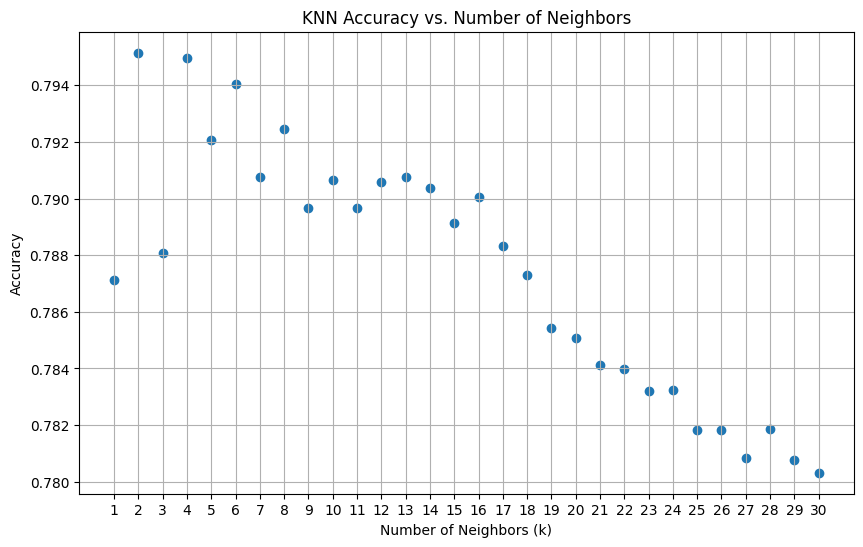

Best k: 2
Highest accuracy: 0.7951534422122657
Accuracy: 0.7803150744327215
Confusion Matrix:
[[10583  1332]
 [ 3228  5614]]


In [ ]:
# Learn means and standard deviations from the training set
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Find the best number of neighbors
k_values = range(1, 31)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    accuracy = accuracy_score(y_test, knn.predict(X_test_scaled))
    accuracies.append(accuracy)
    print(k, accuracy)

# Scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(k_values, accuracies)

plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs. Number of Neighbors')
plt.xticks(range(1, 31))
plt.grid(True)
plt.show()

print("Best k:", k_values[accuracies.index(max(accuracies))])
print("Highest accuracy:", max(accuracies))


# Predict hotel booking cancellations
y_pred = knn.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


In [ ]:
baseline_accuracy = y_test.value_counts(normalize=True).max()
print("Baseline Accuracy:", baseline_accuracy)
# calculate the baseline accuracy
# compare with the knn-model accuracy
# knn-model's accuracy greater than the baseline


Baseline Accuracy: 0.5740232210820446


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.8082349553699971
Recall: 0.6349242252883963
F1 Score: 0.7111730428173296
